In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df_orders = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_orders_dataset.csv")
df_payments = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_order_payments_dataset.csv")
df_customers = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_customers_dataset.csv")
df_products = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_products_dataset.csv")
df_order_items = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_order_items_dataset.csv")

df_payments['Total_Value'] = df_payments['payment_value'] * df_payments['payment_installments']

df_payments_group = df_payments[["order_id", "Total_Value", "payment_type"]].groupby("order_id").sum().reset_index()


df = df_orders.merge(df_customers, on="customer_id", how="left")

df = df.merge(df_payments_group, on="order_id", how="left")


df = df.dropna(subset=["Total_Value"])
df = df[df["Total_Value"] > 0]



#Most Frequent Payment Type

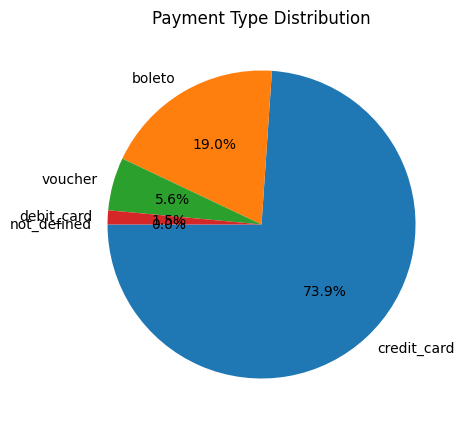

In [3]:


payment_counts = df_payments['payment_type'].value_counts()

plt.figure(figsize=(8,5))
payment_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=180
)

plt.title('Payment Type Distribution')
plt.ylabel('')
plt.show()

#Valor de Parcela


In [4]:
# avg_payment = df.groupby('payment_type')['payment_value'].mean().sort_values(ascending=False)

# plt.figure(figsize=(8,5))
# avg_payment.plot(kind='bar')
# plt.title('Average Payment Value per Payment Type')
# plt.xlabel('Payment Type')
# plt.ylabel('Average Payment Value')
# plt.xticks(rotation=45)
# plt.show()

O valor de parcela com cartão de crédito mais comum é de R$ 50.00

In [5]:



# valor_mais_frequente = df['payment_value'].mode()[0]

# print("Valor que mais se repete:", valor_mais_frequente)

In [6]:


# top_valores = df['payment_value'].value_counts().head(10)

# print(top_valores)

#Recompra e Retenção por Coorte

Coorte é um grupo de clientes que partilha uma característica comum num determinado período.

**Exemplos:**

a. Clientes que fizeram a primeira compra em janeiro

b. Utilizadores que se registaram na mesma semana

c. Clientes adquiridos por uma mesma campanha


Ou seja, **agrupa pessoas pelo momento ou origem de entrada.**

In [13]:
df["order_purchase_timestamp"] = pd.to_datetime(df["order_purchase_timestamp"], format='ISO8601')
df["year_month"] = df["order_purchase_timestamp"].dt.to_period("M")
# df["order_purchase_date_br"] = df["order_purchase_timestamp"].dt.strftime("%d/%m/%y")
df['order_purchase_date_br'] = pd.to_datetime(df['order_purchase_timestamp'], format='%m/%d/%y %H:%M')

display(df.head())

ValueError: Time data 10/2/17 10:56 is not ISO8601 format, at position 0. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [12]:
df['purchase_month_year'] = df['order_purchase_date_br'].dt.to_period('M')

monthly_customer_counts = df.groupby('purchase_month_year')['customer_id'].nunique().reset_index()
monthly_customer_counts = monthly_customer_counts.sort_values('purchase_month_year')

display(monthly_customer_counts)

KeyError: 'order_purchase_date_br'

## Coorte

O e-commerce demonstrou crescimento a partir de Fevereiro/2017 com maior número de clientes únicos em Novembro/2017 ultrapassando 7.500 vendas, seguida de queda no mês de Dezembro/2017 e forte recuperação a partir dessa data.

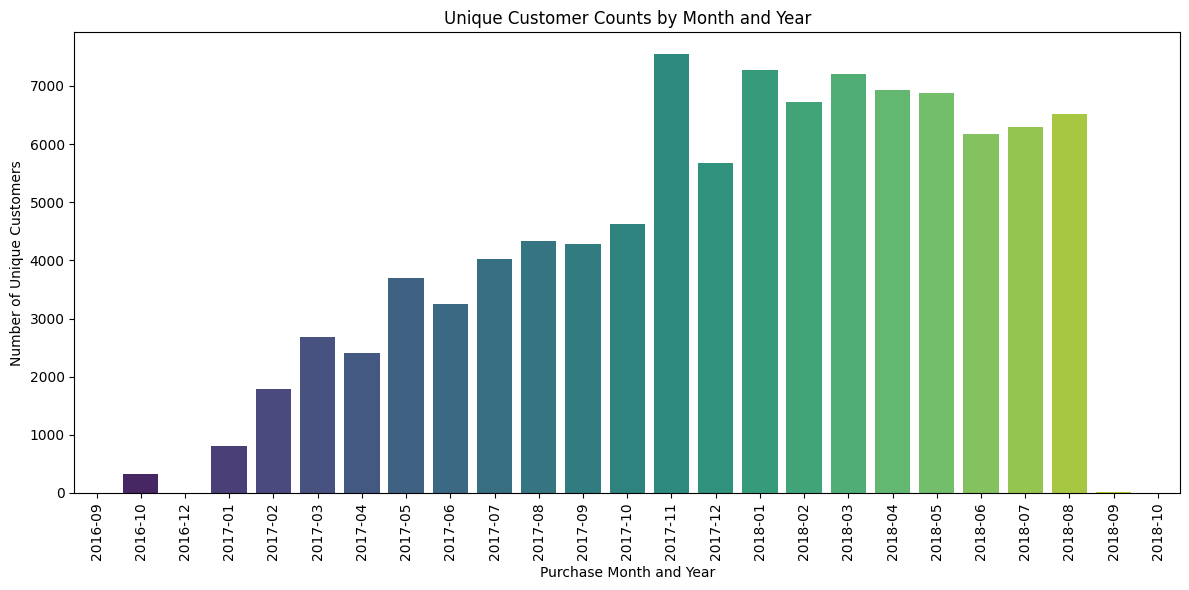

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.barplot(x='purchase_month_year', y='customer_id', data=monthly_customer_counts, palette='viridis', hue='purchase_month_year', legend=False)
plt.title('Unique Customer Counts by Month and Year')
plt.xlabel('Purchase Month and Year')
plt.ylabel('Number of Unique Customers')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
# LTV
# Ticket Médio

In [ ]:

## Célula nova: receita por mês desde 2016

receita_por_mes = df.groupby('purchase_month_year')['Total_Value'].sum().reset_index()
receita_por_mes = receita_por_mes.sort_values('purchase_month_year')

receita_por_mes

,purchase_month_year,Total_Value
0,2016-09,443.31
1,2016-10,311087.22
2,2016-12,19.62
3,2017-01,617745.71
4,2017-02,1195483.77
5,2017-03,2023623.10
6,2017-04,1897830.07
7,2017-05,2644531.62
8,2017-06,2328722.47
9,2017-07,2507170.36


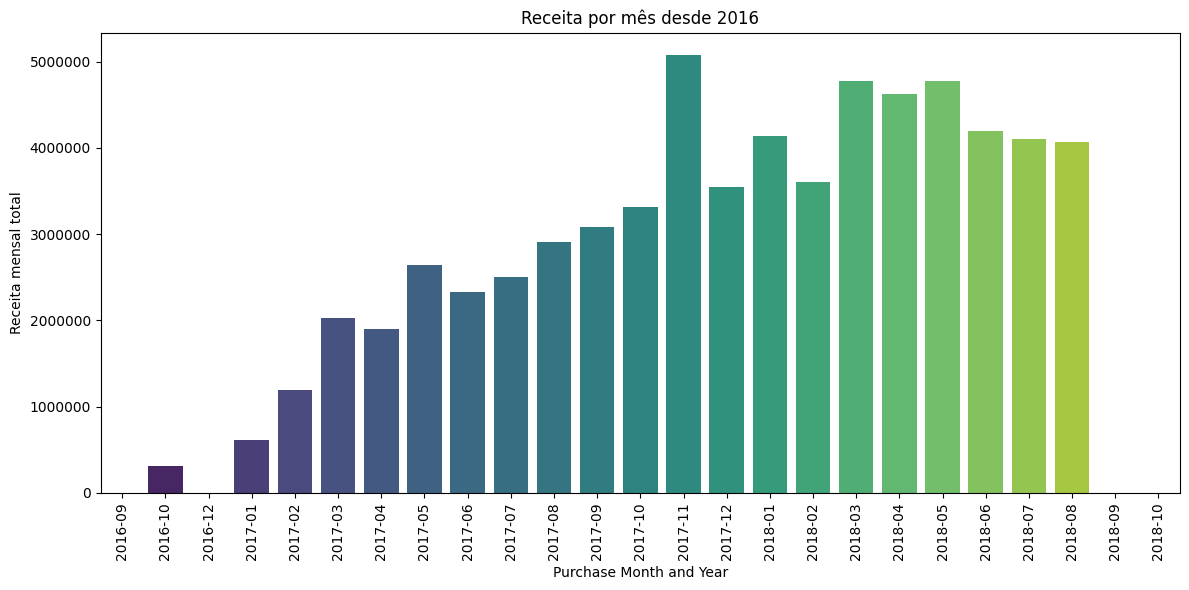

In [ ]:

plt.figure(figsize=(12, 6))
sns.barplot(x='purchase_month_year', y='Total_Value', data=receita_por_mes, palette='viridis', hue='purchase_month_year', legend=False)
plt.title('Receita por mês desde 2016')
plt.xlabel('Purchase Month and Year')
plt.ylabel('Receita mensal total')
plt.xticks(rotation=90)
plt.ticklabel_format(style='plain', axis='y', useOffset=False)
plt.tight_layout()
plt.show()

In [ ]:


print(df[["order_purchase_date_br"]].head())


  order_purchase_date_br
0    2017-10-02 10:56:33
1    2018-07-24 20:41:37
2    2018-08-08 08:38:49
3    2017-11-18 19:28:06
4    2018-02-13 21:18:39


- Criar tabela fato e juntar os datasets
- Criar análise pelo comportamento de compra
- Criar análise para encontrar grupo de clientes que pagam mais e gerar retenção
- Tipos de pagamento por categoria de produto

In [ ]:
orders_per_customer = df.groupby('customer_unique_id')['order_id'].nunique().reset_index()
orders_per_customer.columns = ['customer_unique_id', 'num_orders']

multi_orders_customers = orders_per_customer[orders_per_customer['num_orders'] > 1]

display(multi_orders_customers.head())

,customer_unique_id,num_orders
33,00172711b30d52eea8b313a7f2cced02,2
106,004288347e5e88a27ded2bb23747066c,2
124,004b45ec5c64187465168251cd1c9c2f,2
144,0058f300f57d7b93c477a131a59b36c3,2
249,00a39521eb40f7012db50455bf083460,2


In [ ]:
customer_total_spending = df.groupby('customer_unique_id')['Total_Value'].sum().reset_index()
customer_total_spending.columns = ['customer_unique_id', 'total_spent']

high_value_customers = customer_total_spending[customer_total_spending['total_spent'] > 500.00]
high_value_customers = high_value_customers.sort_values("total_spent", ascending=False)

display(high_value_customers.head(1000))

,customer_unique_id,total_spent
81958,da122df9eeddfedc1dc1f5349a1a690c,75716.30
82804,dc4802a71eae9be1dd28f5d788ceb526,55434.48
33443,58c1b085b54c03a1f1ab5f13d64c2b1c,45970.80
89381,edde2314c6c30e864a128ac95d6b2112,45133.20
93993,fa562ef24d41361e476e748681810e1e,41752.60
...,...,...
75827,c9c0c82af514e815fa47534f71113ebe,8030.08
5832,0f7b92811571afb33b40495374b4dc78,8014.90
90642,f15e3df8a37d94b4e9324f22b58ec5f9,8009.37
55715,94819dfaf894533d1106264e5b378a00,7985.30


In [ ]:
high_value_orders = df[df['Total_Value'] > 499.00]
high_value_order_ids = high_value_orders['order_id'].unique().tolist()

print(f"Number of orders with payment value > 499.00: {len(high_value_order_ids)}")
print("First 5 order_ids with payment value > 499.00:")
for order_id in high_value_order_ids[:5]:
    print(order_id)

Number of orders with payment value > 499.00: 26778
First 5 order_ids with payment value > 499.00:
47770eb9100c2d0c44946d9cf07ec65d
a4591c265e18cb1dcee52889e2d8acc3
dcb36b511fcac050b97cd5c05de84dc3
403b97836b0c04a622354cf531062e5f
95266dbfb7e20354baba07964dac78d5


In [ ]:
unique_customers_high_value_orders = high_value_orders['customer_unique_id'].unique().tolist()

print(f"Number of unique customers who made purchases with payment value > 499.00: {len(unique_customers_high_value_orders)}")
print("First 10 customer_unique_ids who made high-value purchases:")
for customer_id in unique_customers_high_value_orders[:10]:
    print(customer_id)

Number of unique customers who made purchases with payment value > 499.00: 26200
First 10 customer_unique_ids who made high-value purchases:
3a653a41f6f9fc3d2a113cf8398680e8
80bb27c7c16e8f973207a5086ab329e2
ccafc1c3f270410521c3c6f3b249870f
6e26bbeaa107ec34112c64e1ee31c0f5
451e48381edab7f1f6dbfa6d728616ff
576ea0cab426cd8a00fad9a9c90a4494
bd13608b9c6033892ce62269b50a0afc
a6fefcd9f434474cf6fcd8ed1102fd63
5f7d7732b351ce851a158528581af05f
c796780c7daeab9e94cc052b1f103b21


## High Value Customers

Clientes com compras acima de R$499.00

SP, RJ, MG, PR & RS são os estados com maior concentração de clientes de alto valor




In [ ]:

# Filter the main DataFrame to include only the unique high-value customers
high_value_customers_df = df[df['customer_unique_id'].isin(unique_customers_high_value_orders)]

# Get the unique customer_unique_id and their corresponding customer_state
unique_high_value_customer_states = high_value_customers_df.drop_duplicates(subset=['customer_unique_id'])['customer_state']

# Calculate the percentage distribution of customer_state
state_distribution = unique_high_value_customer_states.value_counts(normalize=True) * 100

# Select the top 5 states

state_distribution = state_distribution.reset_index()
top_5_states = state_distribution.head(5)

state_distribution


outros = state_distribution[~state_distribution["customer_state"].isin(state_distribution.head(5)["customer_state"])]

outros["proportion"].sum()


top_5_states.loc[len(top_5_states)] = ("Outros", outros["proportion"].sum())
top_5_states = top_5_states.sort_values("proportion", ascending=False)
top_5_states

/tmp/ipykernel_12402/2385462647.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top_5_states.loc[len(top_5_states)] = ("Outros", outros["proportion"].sum())


,customer_state,proportion
0,SP,35.549618
5,Outros,27.748092
1,RJ,14.026718
2,MG,12.049618
3,RS,5.698473
4,PR,4.927481


<Figure size 1000x800 with 0 Axes>

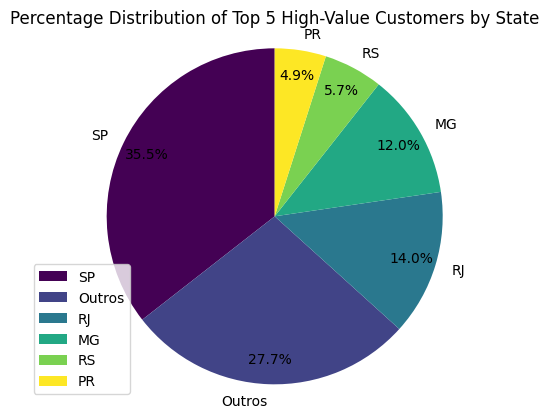

In [ ]:

# Create a pie chart for the top 5 states
plt.figure(figsize=(10, 8))
top_5_states.set_index("customer_state").plot(
    y="proportion",
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    cmap='viridis',
    pctdistance=0.85
)

plt.title('Percentage Distribution of Top 5 High-Value Customers by State')
plt.ylabel('') # Hide the default 'customer_state' label on the y-axis
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

Now I want to know what are the most purchased products by region

In [ ]:

# Carregar datasets (assuming df from u4K_eldryqev is available in kernel state)
# df was created by merging payments, orders, and customers in cell u4K_eldryqev

# Load additional datasets needed for products and order items
order_items = pd.read_csv("olist_order_items_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")

# Define regions
regions = ['SP', 'RJ', 'MG', 'RS', 'PR']

# 1. Filter the existing 'df' for the selected regions.
# 'df' already contains customer_state, order_id, payment_value, customer_unique_id etc.
df_filtered_regions = df[df['customer_state'].isin(regions)]

# # 2. Merge with order_items to get product information
df_with_items = pd.merge(
    df_filtered_regions,
    order_items,
    on='order_id',
    how='inner'
)

# # 3. Merge with products to get product category names
full_data = pd.merge(
    df_with_items,
    products,
    on='product_id',
    how='left'
)


# 5. Agrupar: produtos mais comprados por região
top_products = (
    full_data
    .groupby(['customer_state', 'product_category_name'])
    .size()
    .reset_index(name='purchase_count')
    .sort_values(['customer_state', 'purchase_count'], ascending=[True, False])
)

# 6. Top 10 por região
top_10_per_region = top_products.groupby('customer_state').head(10)

print(top_10_per_region)

    customer_state   product_category_name  purchase_count
13              MG         cama_mesa_banho            1331
11              MG            beleza_saude            1086
42              MG  informatica_acessorios            1000
31              MG           esporte_lazer             966
52              MG        moveis_decoracao             949
69              MG   utilidades_domesticas             835
64              MG      relogios_presentes             637
38              MG      ferramentas_jardim             608
8               MG              automotivo             513
12              MG              brinquedos             494
118             PR        moveis_decoracao             520
100             PR           esporte_lazer             486
82              PR         cama_mesa_banho             468
80              PR            beleza_saude             425
110             PR  informatica_acessorios             389
133             PR   utilidades_domesticas             3

/tmp/ipykernel_12402/1985539005.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_12402/1985539005.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_12402/1985539005.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_12402/1985539005.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_12402/1985539005.py:16: FutureWarning

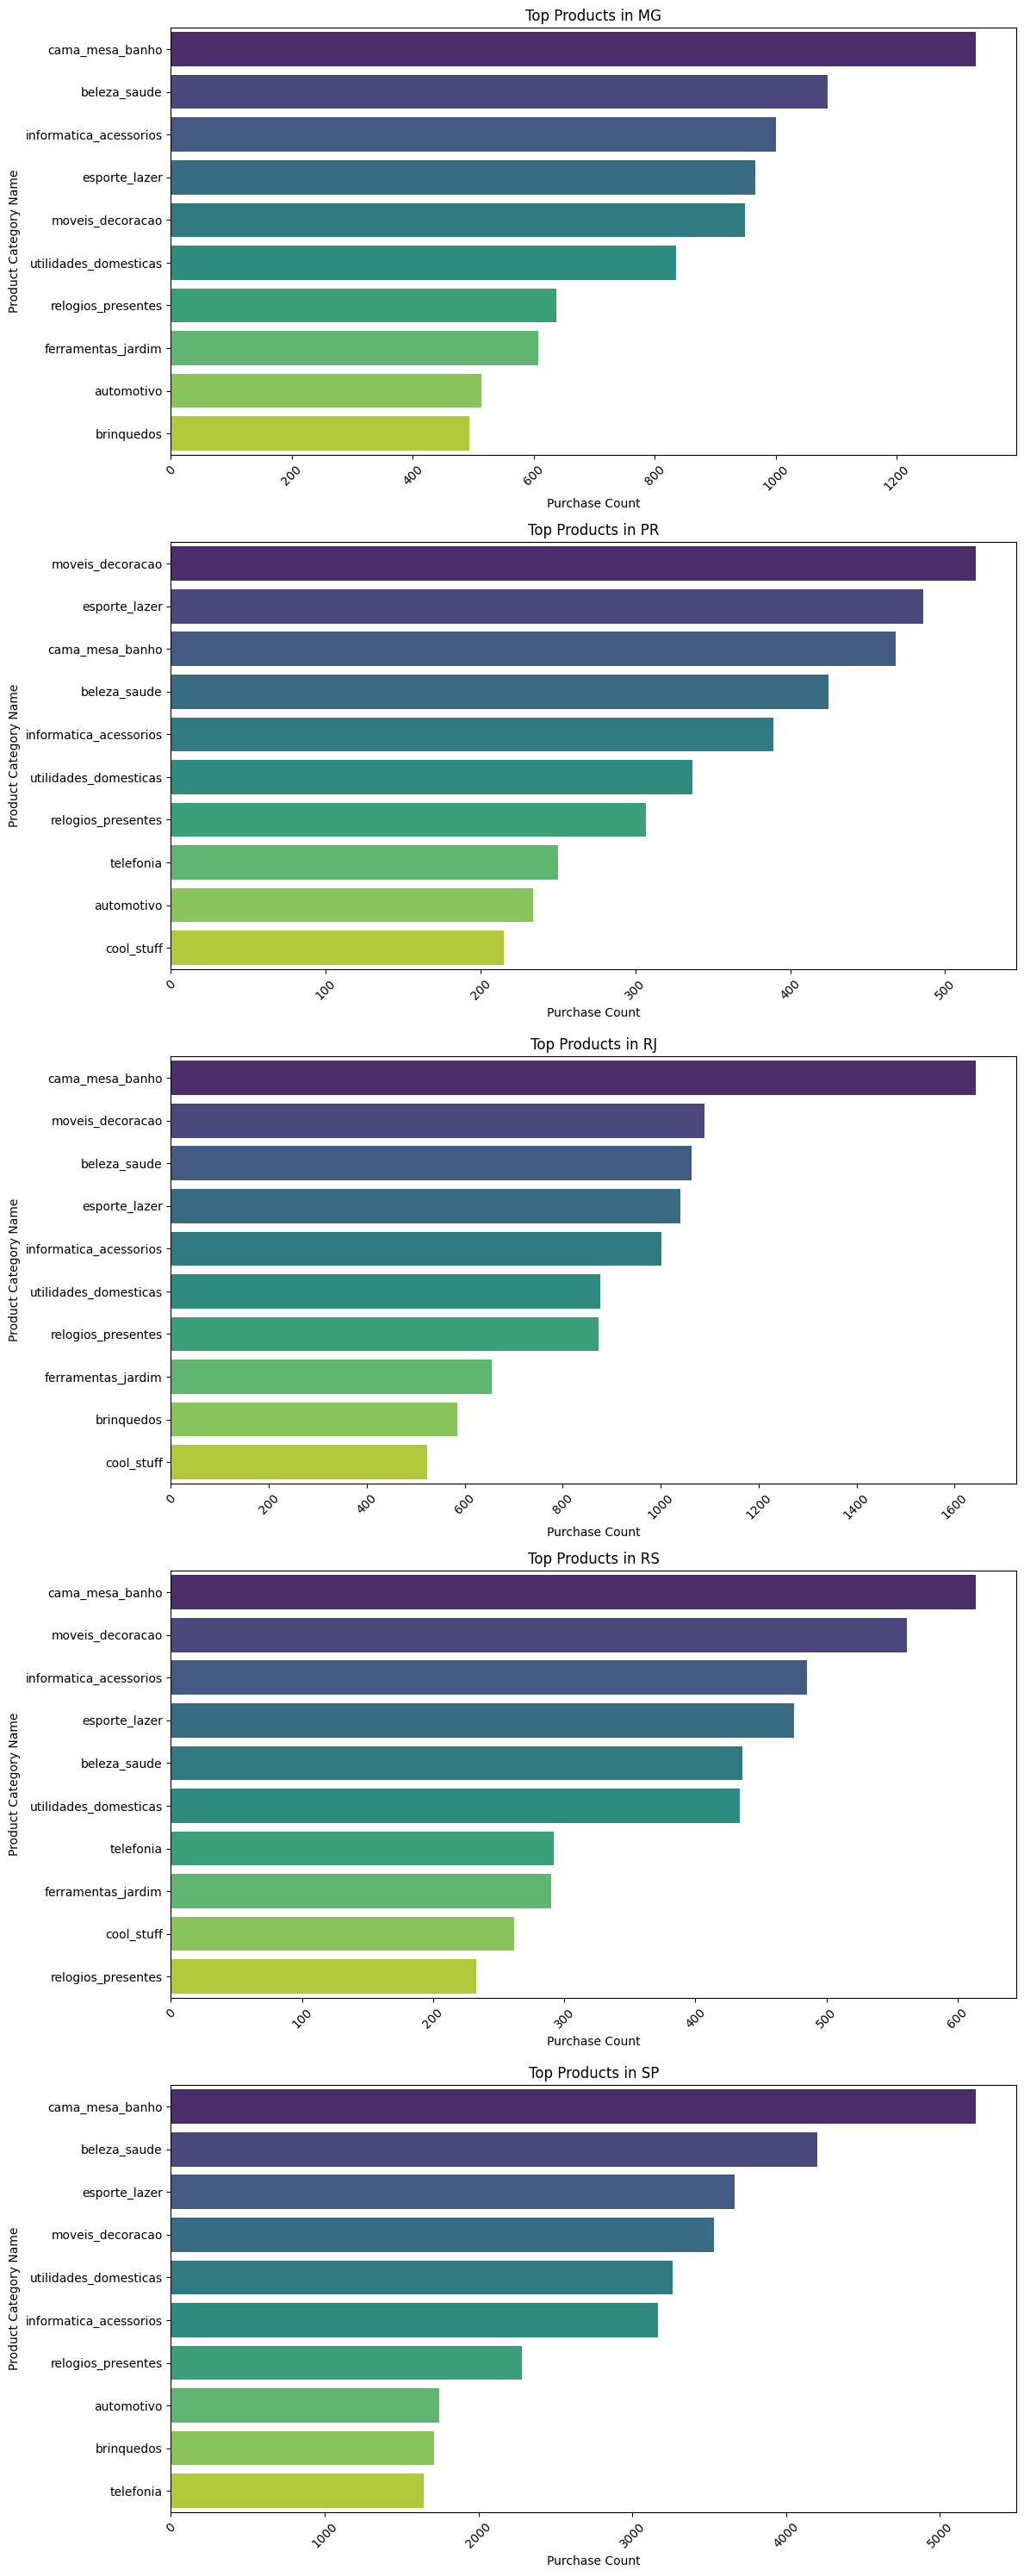

In [ ]:

# Get unique regions from the top_10_per_region DataFrame
unique_regions = top_10_per_region['customer_state'].unique()

# Create a figure with subplots for each region
fig, axes = plt.subplots(len(unique_regions), 1, figsize=(12, 6 * len(unique_regions)))

# Ensure axes is an array even if there's only one region
if len(unique_regions) == 1:
    axes = [axes]

for i, region in enumerate(unique_regions):
    # Filter data for the current region
    region_data = top_10_per_region[top_10_per_region['customer_state'] == region]

    # Create a bar plot for the current region
    sns.barplot(
        x='purchase_count',
        y='product_category_name',
        data=region_data,
        ax=axes[i],
        palette='viridis'
    )

    axes[i].set_title(f'Top Products in {region}')
    axes[i].set_xlabel('Purchase Count')
    axes[i].set_ylabel('Product Category Name')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

These bar charts visually represent the top purchased product categories in each of the selected states. Each bar shows the count of purchases for a specific product category within that state, allowing for easy comparison of popular items across regions.

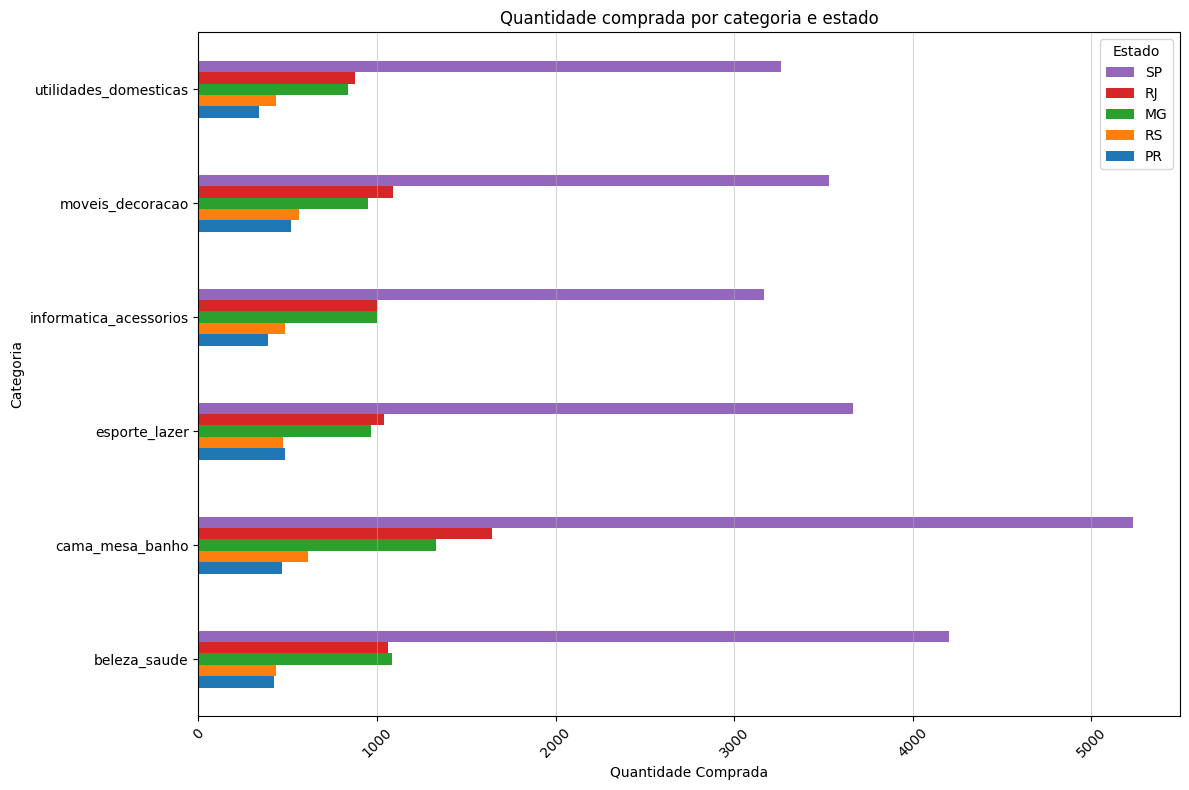

In [ ]:

top_5 = top_products.groupby('customer_state').head(6)


grafico = top_5.pivot(index="product_category_name", columns="customer_state", values="purchase_count")

grafico = grafico[top_5.groupby("customer_state")["purchase_count"].sum().sort_values(ascending=True).index.tolist()]

grafico.plot(kind="barh", figsize=(12, 8))

plt.xlabel("Quantidade Comprada")
plt.ylabel("Categoria")
plt.title("Quantidade comprada por categoria e estado")
plt.xticks(rotation=45)
plt.grid(axis="x", alpha=.5)
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[::-1], labels[::-1], title="Estado")
plt.tight_layout()
plt.show()


In [ ]:


financial_impact_per_region = df.groupby('customer_state')['Total_Value'].sum().reset_index()

financial_impact_per_region = financial_impact_per_region.sort_values(by='Total_Value', ascending=False)


outros = financial_impact_per_region[~financial_impact_per_region["customer_state"].isin(financial_impact_per_region.head(5)["customer_state"])]

outros.sum()

financial_impact_per_region = financial_impact_per_region.head(5)

financial_impact_per_region.loc[len(financial_impact_per_region)] = ("Outros", outros.reset_index()["Total_Value"].sum())
financial_impact_per_region = financial_impact_per_region.sort_values("Total_Value", ascending=False)
financial_impact_per_region

,customer_state,Total_Value
25,SP,22957582.55
5,Outros,18992492.78
18,RJ,8957369.67
10,MG,7810151.16
22,RS,3697793.99
17,PR,3347767.47


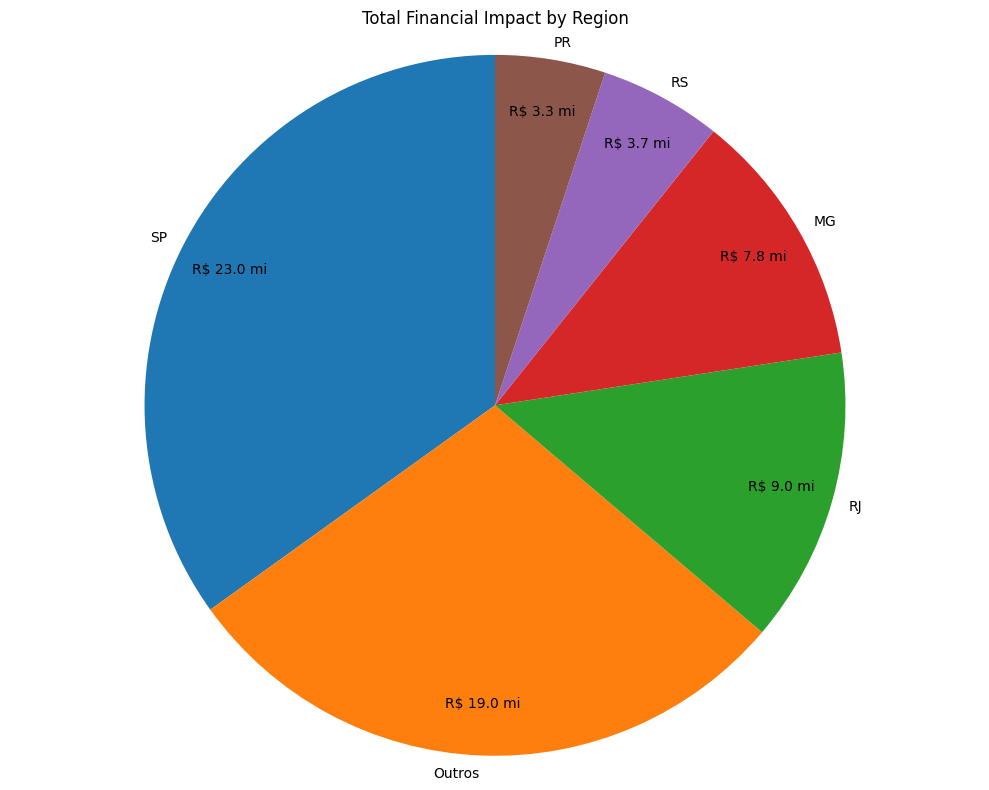

In [ ]:

plt.figure(figsize=(10, 8))
plt.pie(
    financial_impact_per_region['Total_Value'],
    labels=financial_impact_per_region['customer_state'],
    autopct=lambda p: f'R$ {(p*sum(financial_impact_per_region['Total_Value'])/100)/1_000_000:.1f} mi',
    startangle=90,
    pctdistance=0.85,
    labeldistance=1.05
)

plt.title('Total Financial Impact by Region')
plt.axis('equal')
plt.tight_layout()
plt.show()

This bar chart displays the total payment value (financial impact) for each of the selected regions. You can now easily see which states contribute the most in terms of sales revenue.

In [ ]:


# zoom-in em novembro -> produtos mais comprados
# cálculo do LTV
# adicionar "outros" aos gráficos de pizza



In [ ]:
receita_por_mes = df.groupby('purchase_month_year')['Total_Value'].sum().reset_index()
receita_por_mes = receita_por_mes.sort_values('purchase_month_year')

receita_por_mes

,purchase_month_year,Total_Value
0,2016-09,443.31
1,2016-10,311087.22
2,2016-12,19.62
3,2017-01,617745.71
4,2017-02,1195483.77
5,2017-03,2023623.10
6,2017-04,1897830.07
7,2017-05,2644531.62
8,2017-06,2328722.47
9,2017-07,2507170.36


In [ ]:
# zoom-in em novembro 2017 -> categorias de produtos com maior receita

df_november = df.merge(df_order_items, on="order_id", how="left")

df_november = df_november.merge(df_products, on="product_id", how="left")

df_november = df_november[(df_november["order_purchase_timestamp"].dt.month == 11) & (df_november["order_purchase_timestamp"].dt.year == 2017)]
df_november.groupby("product_category_name")["Total_Value"].sum().sort_values(ascending=False).head(10)





,Total_Value
product_category_name,
cama_mesa_banho,756021.45
moveis_decoracao,739678.22
relogios_presentes,586201.83
informatica_acessorios,509916.96
beleza_saude,427370.75
moveis_sala,378783.66
brinquedos,354796.29
ferramentas_jardim,348643.22
cool_stuff,337907.61


In [ ]:
# LTV

customer_total_spending = df.groupby('customer_unique_id')['Total_Value'].sum().reset_index()
customer_total_spending.columns = ['customer_unique_id', 'total_spent']

# high_value_customers = customer_total_spending[customer_total_spending['total_spent'] > 500.00]
customer_total_spending = customer_total_spending.sort_values("total_spent", ascending=False)

display(customer_total_spending)

print("Média de LTV:")
display(customer_total_spending["total_spent"].sum() / len(customer_total_spending))

,customer_unique_id,total_spent
81958,da122df9eeddfedc1dc1f5349a1a690c,75716.30
82804,dc4802a71eae9be1dd28f5d788ceb526,55434.48
33443,58c1b085b54c03a1f1ab5f13d64c2b1c,45970.80
89381,edde2314c6c30e864a128ac95d6b2112,45133.20
93993,fa562ef24d41361e476e748681810e1e,41752.60
...,...,...
41891,6f5b9d1cdccc4d28f0483a612edecacf,11.63
15236,2878e5b88167faab17d4fb83a986d38b,11.63
67384,b33336f46234b24a613ad9064d13106d,10.89
71048,bd06ce0e06ad77a7f681f1a4960a3cc6,10.07


Média de LTV:


np.float64(684.3841527302246)